# 03 · LangGraph

**Module 06 · Agent Frameworks**

**LangGraph** asks you to **draw the flow** of your system as a graph:

| Idea | What it is |
|---|---|
| **State** | A shared notebook that every step can read and add to |
| **Node** | A box that does one job. It is just a Python function. |
| **Edge** | An arrow that says what comes next |
| **Conditional edge** | An arrow that picks the next box by looking at the state |

Nothing is left to the model's judgement unless you choose it. That gives you **control**. In return, you write more of the structure yourself.

In [1]:
from typing import Literal, TypedDict
from pydantic import BaseModel
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langgraph.graph import StateGraph, START, END

import shop_tools as shop

llm = ChatOpenAI(model=shop.MODEL, temperature=0)  # the model every node will use

print("Ready")

Ready


## 1. A first graph with no AI at all
The best way to learn the idea is a graph that uses **no model**. We check an email for alarming words, then send it either to a person or to the automatic desk.

In [2]:
# The STATE: the notebook every node can read and write
class TicketState(TypedDict):
    email: str
    urgent: bool
    outcome: str


def spot_urgent(state):
    """Node 1: look for alarming words. A node returns only the parts of the state it changes."""
    alarming_words = ["lawyer", "sue", "fraud", "police"]
    found = False
    for word in alarming_words:
        if word in state["email"].lower():
            found = True
    return {"urgent": found}


def human_node(state):
    return {"outcome": "A person will call the customer today."}


def auto_node(state):
    return {"outcome": "The desk replies automatically."}


def pick_next(state):
    """The conditional edge: read the state and return the name of the next node."""
    if state["urgent"]:
        return "human"
    return "auto"


# Draw the graph: add the boxes, then the arrows
builder = StateGraph(TicketState)
builder.add_node("spot_urgent", spot_urgent)
builder.add_node("human", human_node)
builder.add_node("auto", auto_node)

builder.add_edge(START, "spot_urgent")
builder.add_conditional_edges("spot_urgent", pick_next, {"human": "human", "auto": "auto"})
builder.add_edge("human", END)
builder.add_edge("auto", END)

ticket_graph = builder.compile()  # turn the drawing into something we can run

In [3]:
for email in ["Where is my order?", "Fix this today or I will contact my lawyer."]:
    final_state = ticket_graph.invoke({"email": email})
    print(email, "->", final_state["outcome"])

Where is my order? -> The desk replies automatically.
Fix this today or I will contact my lawyer. -> A person will call the customer today.


The graph can also describe itself. This text is in **Mermaid** format. Paste it into [mermaid.live](https://mermaid.live) to see the picture.

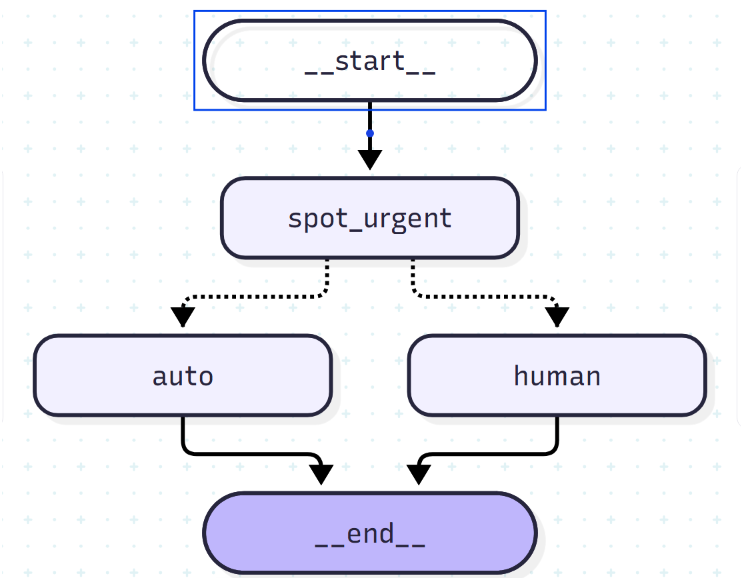

In [12]:
print(ticket_graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	spot_urgent(spot_urgent)
	human(human)
	auto(auto)
	__end__([<p>__end__</p>]):::last
	__start__ --> spot_urgent;
	spot_urgent -.-> auto;
	spot_urgent -.-> human;
	auto --> __end__;
	human --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



## 2. The support desk as a graph
Now the real desk. First the three specialists. `create_agent` builds a complete tool-using agent (the loop **and** the tool descriptions) from our plain functions.

In [5]:
# create_agent builds a complete tool-using agent: the loop AND the tool descriptions.
# Our plain functions work as tools as they are (the docstring and type hints describe them).
orders_agent = create_agent(llm, tools=[shop.lookup_order], system_prompt=shop.ORDERS_INSTRUCTIONS)
policy_agent = create_agent(llm, tools=[shop.search_policies], system_prompt=shop.POLICY_INSTRUCTIONS)
refunds_agent = create_agent(llm, tools=[shop.check_refund_eligibility, shop.issue_refund], system_prompt=shop.REFUNDS_INSTRUCTIONS)

Next the graph: a **route** node that picks the specialist, three specialist nodes, and a conditional edge between them.

The router can only answer `orders`, `policy` or `refunds`, because its answer is typed as a `Literal`. A model cannot invent a fourth specialist.

In [6]:
# The STATE is a shared notebook that every node can read and add to.
class DeskState(TypedDict):
    email: str
    specialist: str
    reply: str


class Route(BaseModel):
    specialist: Literal["orders", "policy", "refunds"]  # the model can only pick one of these three


def route_node(state):
    """Node 1: decide which specialist should handle the email."""
    router = llm.with_structured_output(Route)
    route = router.invoke(
        "Pick the specialist for this customer email. "
        "orders = where an order is or what is in it. "
        "policy = shop rules such as shipping, warranty or payments. "
        "refunds = the customer wants their money back.\n\nEmail: " + state["email"])
    return {"specialist": route.specialist}  # a node returns only the parts of the state it changes


def make_specialist_node(agent):
    """Wrap a specialist agent so it can sit in the graph as a node."""
    def node(state):
        result = agent.invoke({"messages": [{"role": "user", "content": state["email"]}]})
        return {"reply": result["messages"][-1].content}
    return node


def pick_specialist(state):
    """The conditional edge: read the state and return the name of the next node."""
    return state["specialist"]


builder = StateGraph(DeskState)
builder.add_node("route", route_node)
builder.add_node("orders", make_specialist_node(orders_agent))
builder.add_node("policy", make_specialist_node(policy_agent))
builder.add_node("refunds", make_specialist_node(refunds_agent))

builder.add_edge(START, "route")
builder.add_conditional_edges("route", pick_specialist, {"orders": "orders", "policy": "policy", "refunds": "refunds"})
builder.add_edge("orders", END)
builder.add_edge("policy", END)
builder.add_edge("refunds", END)

desk_graph = builder.compile()  # turn the drawing into something we can run

In [7]:
print(desk_graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	route(route)
	orders(orders)
	policy(policy)
	refunds(refunds)
	__end__([<p>__end__</p>]):::last
	__start__ --> route;
	route -.-> orders;
	route -.-> policy;
	route -.-> refunds;
	orders --> __end__;
	policy --> __end__;
	refunds --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



# Langflow Diagram

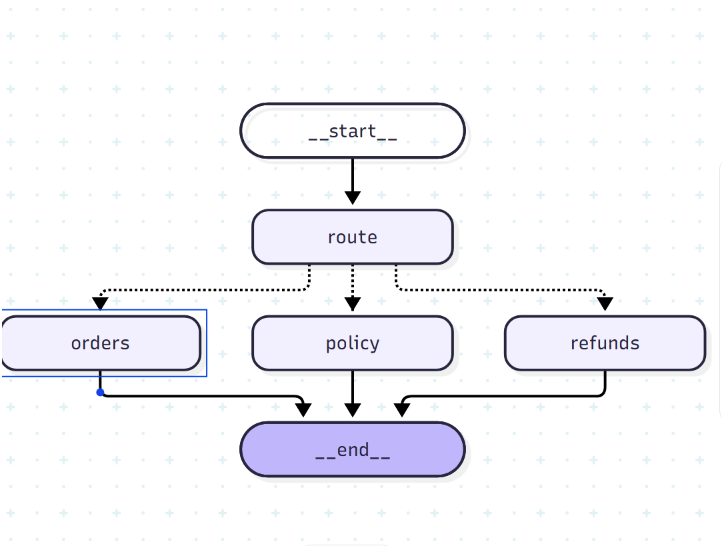

Now we run it. `stream` lets us watch the graph **one node at a time**, which is how you see exactly where a flow went.

In [8]:
emails = [
    "Hi, can you tell me where my order A1002 is?",
    "How much does express shipping cost?",
    "The left earbud on my headphones (order A1001) stopped working. I would like my money back.",
]

for email in emails:
    shop.reset_shop()
    print("Email:", email)
    for step in desk_graph.stream({"email": email}):
        for node_name in step:
            print("  node '" + node_name + "' ran and set:", list(step[node_name].keys()))
    print("  Tools that ran:", shop.TOOL_CALLS)
    print("  Refunds issued:", shop.REFUNDS)
    print()

Email: Hi, can you tell me where my order A1002 is?
  node 'route' ran and set: ['specialist']
  node 'orders' ran and set: ['reply']
  Tools that ran: ['lookup_order']
  Refunds issued: []

Email: How much does express shipping cost?
  node 'route' ran and set: ['specialist']
  node 'policy' ran and set: ['reply']
  Tools that ran: ['search_policies']
  Refunds issued: []

Email: The left earbud on my headphones (order A1001) stopped working. I would like my money back.
  node 'route' ran and set: ['specialist']
  node 'refunds' ran and set: ['reply']
  Tools that ran: ['check_refund_eligibility', 'issue_refund']
  Refunds issued: [{'order_id': 'A1001', 'amount': 79.0}]



## 3. LangGraph's superpower: pause for a human, then resume
In Module 05 a refund over $100 waited for a human to approve it. In LangGraph, **pausing is a built-in feature**.

Two pieces make it work:
- A **checkpointer** saves the state after every node, so a paused graph can be picked up later. (Here it lives in memory. In production you would use a database.)
- `interrupt(...)` stops the graph and hands a question to the outside world. Running the graph again with `Command(resume=...)` continues from that exact point.

In [9]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt, Command


class RefundState(TypedDict):
    order_id: str
    amount: float
    approved: bool
    result: str


def check_node(state):
    """Look up how much the refund would be."""
    order = shop.ORDERS[state["order_id"]]
    return {"amount": order["price"]}


def needs_human(state):
    """Big refunds go to a human. Small ones are issued straight away."""
    if state["amount"] > 100:
        return "ask_human"
    return "issue"


def ask_human_node(state):
    """Stop here and ask. The graph resumes when someone answers."""
    answer = interrupt("Refund of $" + str(state["amount"]) + " for order " + state["order_id"] + ". Approve? (yes/no)")
    return {"approved": answer == "yes"}


def after_human(state):
    if state["approved"]:
        return "issue"
    return "refused"


def issue_node(state):
    return {"result": shop.issue_refund(state["order_id"])}


def refused_node(state):
    return {"result": "A human declined the refund."}


builder = StateGraph(RefundState)
builder.add_node("check", check_node)
builder.add_node("ask_human", ask_human_node)
builder.add_node("issue", issue_node)
builder.add_node("refused", refused_node)

builder.add_edge(START, "check")
builder.add_conditional_edges("check", needs_human, {"ask_human": "ask_human", "issue": "issue"})
builder.add_conditional_edges("ask_human", after_human, {"issue": "issue", "refused": "refused"})
builder.add_edge("issue", END)
builder.add_edge("refused", END)

refund_graph = builder.compile(checkpointer=InMemorySaver())

A $250 television refund. The graph runs until it reaches `interrupt`, then **stops and waits**. The `thread_id` is the name of this ticket, so we can come back to it.

In [10]:
shop.reset_shop()
ticket = {"configurable": {"thread_id": "ticket-1"}}

state = refund_graph.invoke({"order_id": "A1004"}, ticket)

print("The graph is waiting. The question for the human:")
print("  ", state["__interrupt__"][0].value)
print("Refunds issued so far:", shop.REFUNDS)
print("Next node to run:", refund_graph.get_state(ticket).next)

The graph is waiting. The question for the human:
   Refund of $250.0 for order A1004. Approve? (yes/no)
Refunds issued so far: []
Next node to run: ('ask_human',)


Nothing has been refunded. The graph could wait for a minute or a week. Now the human says yes:

In [11]:
state = refund_graph.invoke(Command(resume="yes"), ticket)

print("Result:", state["result"])
print("Refunds issued:", shop.REFUNDS)

Result: Refund of $250.00 issued for order A1004.
Refunds issued: [{'order_id': 'A1004', 'amount': 250.0}]


It continued from exactly where it stopped. Doing this by hand (Module 05) meant storing the pending refund ourselves. Here the framework saves and restores the state.

## 4. What it costs
- **More to learn.** State, nodes, edges, conditional edges and checkpointers is the longest vocabulary of the three.
- **You write the routing.** The model does not decide the flow. You do. That is the point, and also more code.
- **LangChain pieces appear.** Models, tools and `create_agent` come from the LangChain family of packages.
- **Fast-moving.** Older tutorials use calls that are now deprecated (for example `create_react_agent`). Check the version.

**Pick it when** the flow matters: loops, branches, saved progress, human approval, or a process you must be able to explain step by step.

Next: **CrewAI**, where agents work like a team.